# v5.6 전술 클러스터링 심층 분석

이 노트북은 **좌표 기반 궤적 특징**과 **6x3 그리드 기반 OPTICS 클러스터링**을 적용한 v5.6 버전의 결과를 분석합니다.

### 분석 포인트
1. **공간적 밀집도**: 어떤 그리드 지역에서 전술적 패턴이 명확하게 나타나는가?
2. **전술적 일관성**: 클러스터링된 시퀀스들이 실제로 유사한 궤적을 보이는가?
3. **성과와의 연결**: 특정 전술 패턴이 높은 성공률이나 특정 성과(Outcome)와 연계되는가?
4. **팀별 비교**: 상위 팀들 간의 공격 패턴 차이는 무엇인가?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import os
import matplotlib.patches as patches

# 한글 폰트 설정 (Windows 기준)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="white", font="Malgun Gothic")

import warnings
warnings.filterwarnings('ignore')

In [2]:
# [소프트 코딩] 설정 및 데이터 로드
CONFIG_PATH = '../config.yaml'
with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
    config = yaml.safe_load(f)

VERSION = config['version']
BASE_DIR = '..'
REFINED_DIR = f"{BASE_DIR}/data/refined/{VERSION}/"

print(f"분석 버전: {VERSION}")
print(f"데이터 경로: {REFINED_DIR}")

try:
    cluster_df = pd.read_csv(REFINED_DIR + 'cluster_labels.csv', encoding='utf-8-sig')
    stats_df = pd.read_csv(REFINED_DIR + 'attack_sequences_stats.csv', encoding='utf-8-sig')
    cluster_stats = pd.read_csv(REFINED_DIR + 'cluster_stats.csv', encoding='utf-8-sig')
    
    # 데이터 병합
    merged = stats_df.merge(cluster_df, on='sequence_id', how='inner')
    print(f"로드 완료: {len(merged):,}개 시퀀스")
except FileNotFoundError as e:
    print(f"파일을 찾을 수 없습니다: {e}")

분석 버전: v5.6
데이터 경로: ../data/refined/v5.6/
로드 완료: 151개 시퀀스


## 1. 클러스터 분포 분석

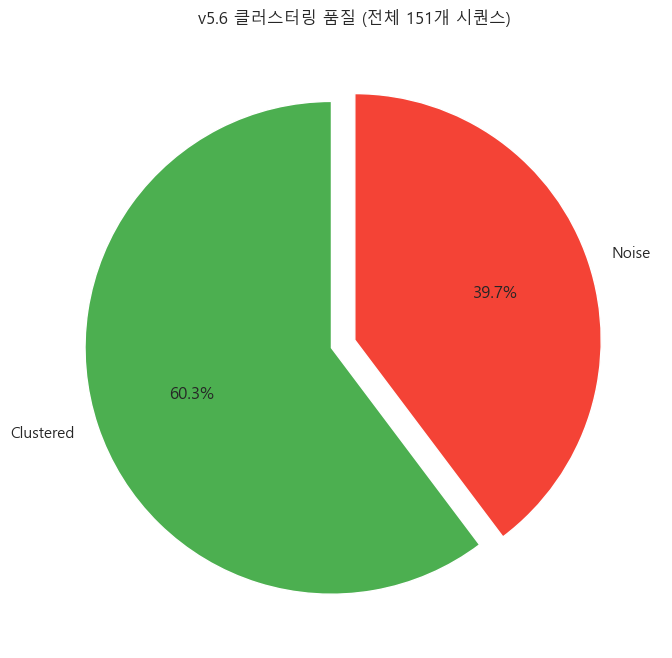

총 클러스터 수: 5개


In [3]:
# 클러스터 vs 노이즈 비율
is_noise = merged['cluster'] == -1
noise_counts = is_noise.value_counts()

plt.figure(figsize=(8, 8))
plt.pie(noise_counts, labels=['Clustered', 'Noise'], autopct='%1.1f%%', 
        startangle=90, colors=['#4CAF50', '#F44336'], explode=(0.1, 0))
plt.title(f'v5.6 클러스터링 품질 (전체 {len(merged)}개 시퀀스)')
plt.show()

print(f"총 클러스터 수: {merged['cluster'].max() + 1}개")

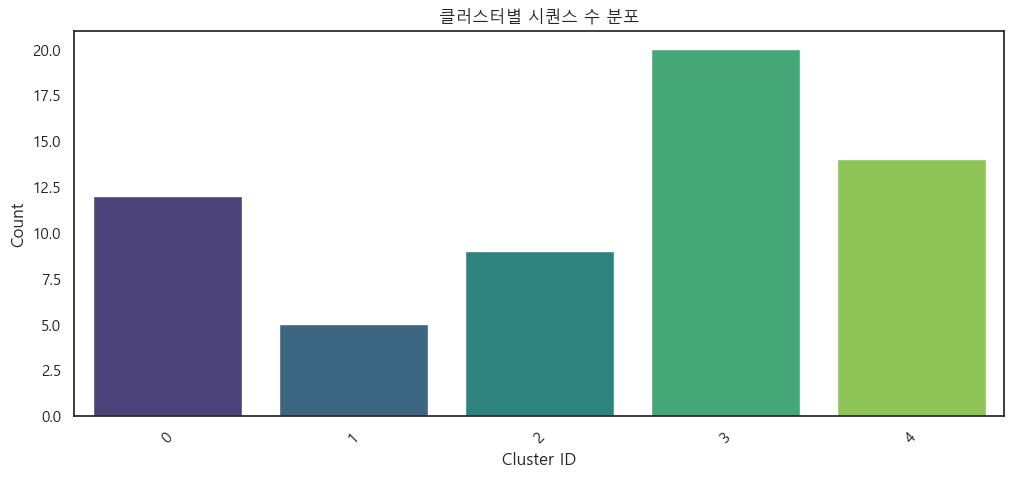

In [4]:
# 클러스터 크기 분포
plt.figure(figsize=(12, 5))
cluster_counts = merged[merged['cluster'] >= 0]['cluster'].value_counts().sort_index()
sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis')
plt.title('클러스터별 시퀀스 수 분포')
plt.xlabel('Cluster ID')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

## 2. 전술적 특성 분석 (Tempo & Success Rate)

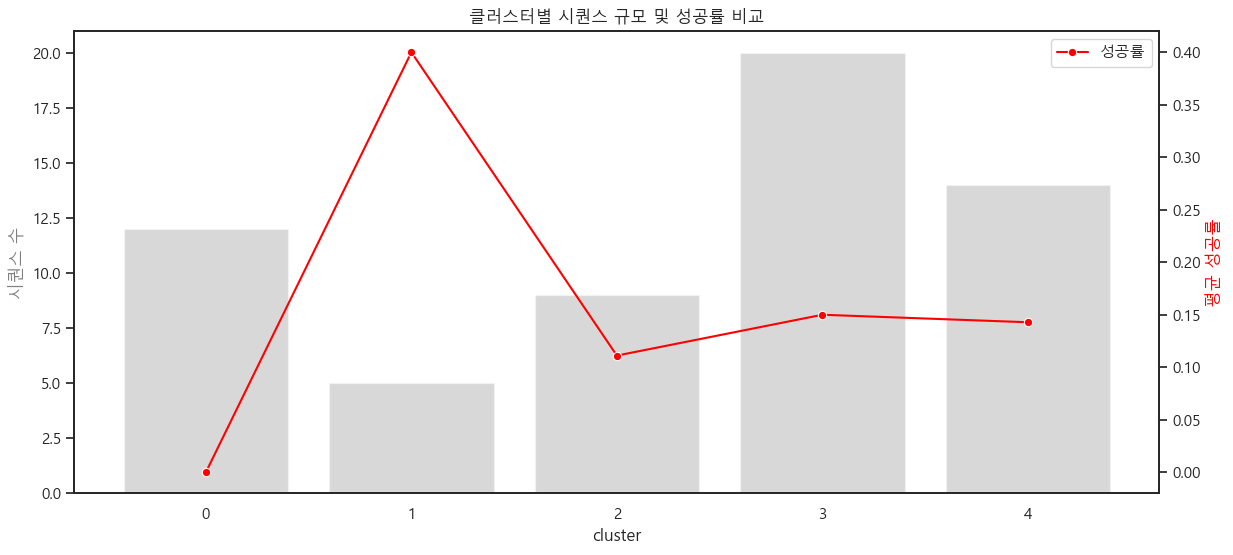

In [5]:
# 클러스터별 평균 템포 및 성공률 시각화
valid_clusters = cluster_stats[cluster_stats['cluster'] >= 0]

fig, ax1 = plt.subplots(figsize=(14, 6))

ax2 = ax1.twinx()
sns.barplot(data=valid_clusters, x='cluster', y='count', ax=ax1, alpha=0.3, color='gray')
sns.lineplot(data=valid_clusters, x=range(len(valid_clusters)), y='success_rate', ax=ax2, marker='o', color='red', label='성공률')

ax1.set_ylabel('시퀀스 수', color='gray')
ax2.set_ylabel('평균 성공률', color='red')
plt.title('클러스터별 시퀀스 규모 및 성공률 비교')
plt.show()

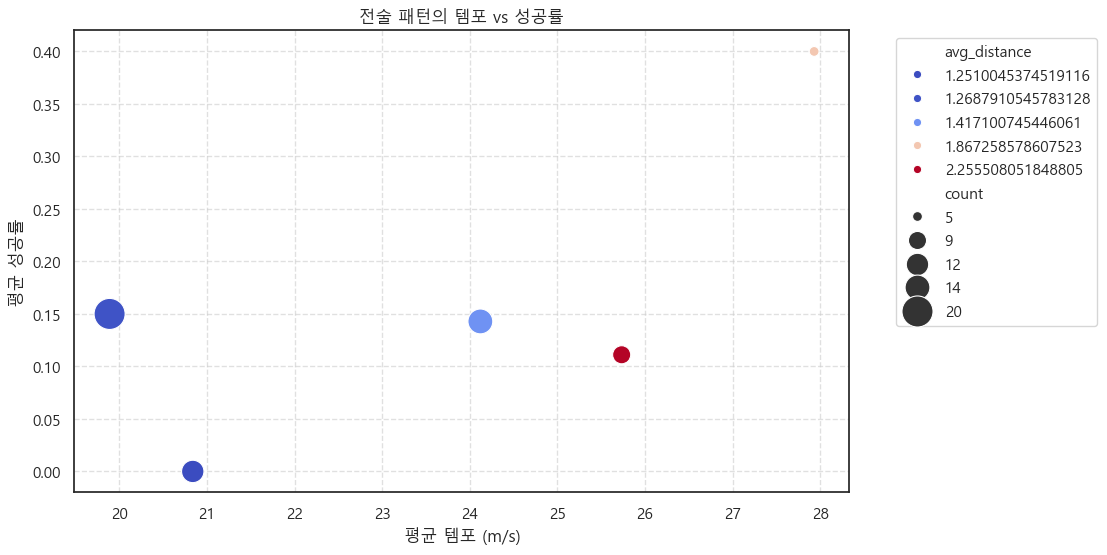

In [6]:
# 템포(Speed)와 성공률의 관계
plt.figure(figsize=(10, 6))
sns.scatterplot(data=valid_clusters, x='avg_tempo', y='success_rate', size='count', hue='avg_distance', palette='coolwarm', sizes=(50, 500))
plt.title('전술 패턴의 템포 vs 성공률')
plt.xlabel('평균 템포 (m/s)')
plt.ylabel('평균 성공률')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 3. 공간 패턴 분석 (6x3 그리드)

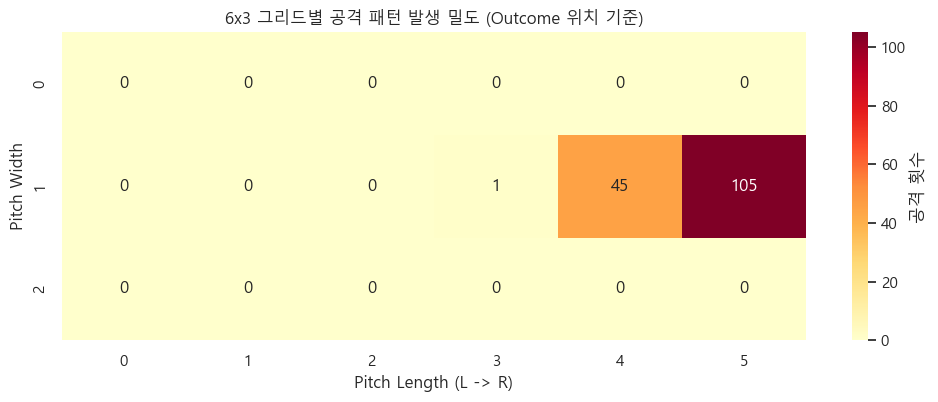

In [7]:
# 6x3 그리드 공격 발생 히트맵
grid_counts = merged.groupby(['grid_id']).size().reset_index(name='count')

# 6x3 매트릭스로 변환 (y_bins=3, x_bins=6)
heatmap_data = np.zeros((3, 6))
for _, row in grid_counts.iterrows():
    if row['grid_id'] == -1: continue
    y = int(row['grid_id'] // 6)
    x = int(row['grid_id'] % 6)
    heatmap_data[y, x] = row['count']

plt.figure(figsize=(12, 4))
sns.heatmap(heatmap_data, annot=True, fmt='g', cmap='YlOrRd', cbar_kws={'label': '공격 횟수'})
plt.title('6x3 그리드별 공격 패턴 발생 밀도 (Outcome 위치 기준)')
plt.xlabel('Pitch Length (L -> R)')
plt.ylabel('Pitch Width')
plt.show()

## 4. 궤적 시각화 (대표 클러스터)

In [8]:
def draw_pitch(ax):
    # 축구장 그리기 (0-1 정규화 좌표 기준)
    pitch = patches.Rectangle((0, 0), 1, 1, edgecolor="black", facecolor="none", zorder=0)
    ax.add_patch(pitch)
    
    # 센터라인, 박스 등 약식 표시
    plt.plot([0.5, 0.5], [0, 1], color="black", lw=1, zorder=0)
    plt.plot([0, 0.16], [0.2, 0.2], color="black", lw=1, zorder=0)
    plt.plot([0, 0.16], [0.8, 0.8], color="black", lw=1, zorder=0)
    plt.plot([0.16, 0.16], [0.2, 0.8], color="black", lw=1, zorder=0)
    
    plt.plot([1, 0.84], [0.2, 0.2], color="black", lw=1, zorder=0)
    plt.plot([1, 0.84], [0.8, 0.8], color="black", lw=1, zorder=0)
    plt.plot([0.84, 0.84], [0.2, 0.8], color="black", lw=1, zorder=0)
    
    circle = patches.Circle((0.5, 0.5), 0.09, edgecolor="black", facecolor="none", lw=1, zorder=0)
    ax.add_patch(circle)

def visualize_cluster_trajectories(cluster_id, n_samples=20):
    samples = merged[merged['cluster'] == cluster_id].sample(min(n_samples, len(merged[merged['cluster'] == cluster_id])))
    
    fig, ax = plt.subplots(figsize=(10, 6.4))
    draw_pitch(ax)
    
    for _, row in samples.iterrows():
        # 간략화된 궤적 (시작 -> 끝)
        plt.arrow(row['start_x'], row['start_y'], 
                  row['end_x'] - row['start_x'], row['end_y'] - row['start_y'], 
                  head_width=0.02, head_length=0.03, fc='blue', ec='blue', alpha=0.3)
        plt.scatter(row['start_x'], row['start_y'], color='green', s=10, alpha=0.5)
        plt.scatter(row['end_x'], row['end_y'], color='red', s=20, alpha=0.8)
    
    plt.title(f'Cluster {cluster_id} 궤적 샘플 (n={len(samples)})')
    plt.xlim(-0.05, 1.05)
    plt.ylim(-0.05, 1.05)
    plt.axis('off')
    plt.show()

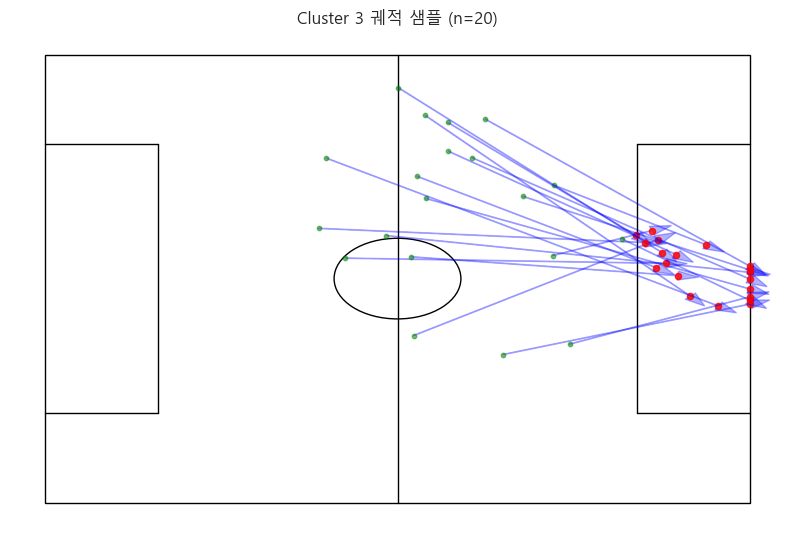

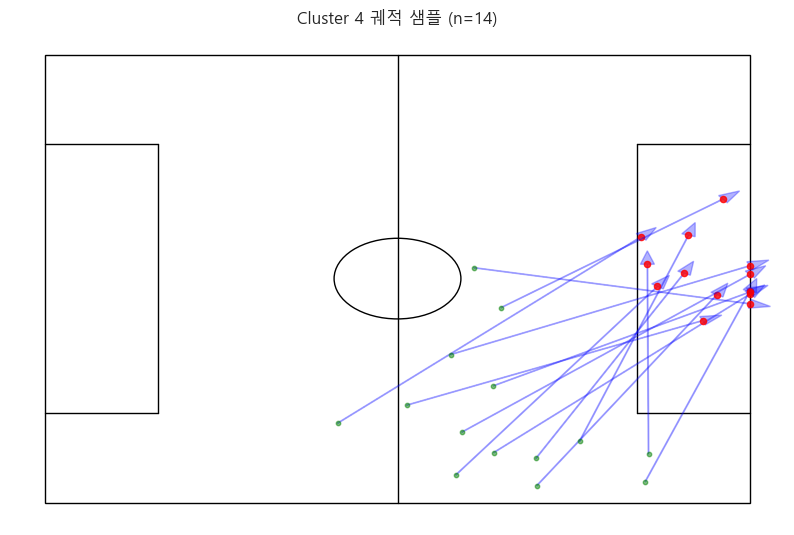

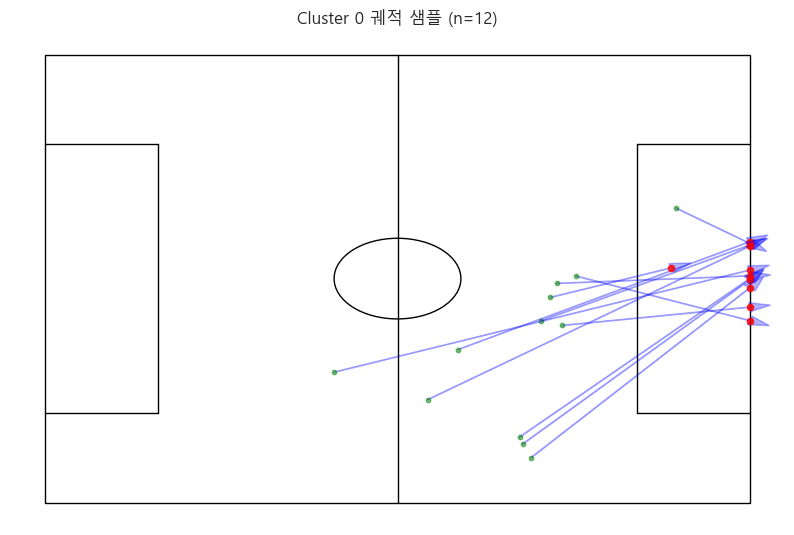

In [9]:
# 상위 3개 클러스터 시각화
top_clusters = valid_clusters.sort_values('count', ascending=False).head(3)['cluster'].values
for cid in top_clusters:
    visualize_cluster_trajectories(cid)

## 5. 팀별 전술 비교

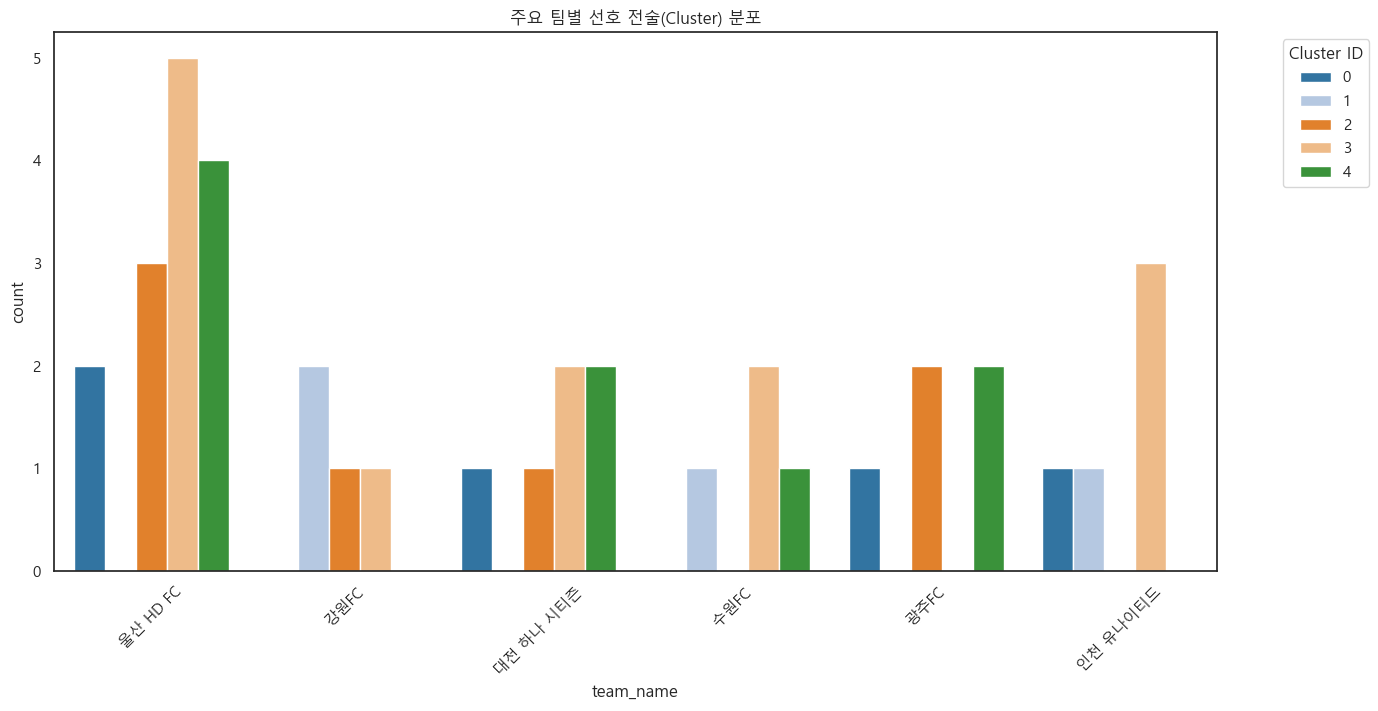

: 

In [ ]:
# 팀 이름 매핑 정보 로드 (필요시)
match_info = pd.read_csv(f"{BASE_DIR}/{config['data']['match_info_path']}")
team_names = match_info[['home_team_id', 'home_team_name_ko']].drop_duplicates().set_index('home_team_id')['home_team_name_ko'].to_dict()
away_names = match_info[['away_team_id', 'away_team_name_ko']].drop_duplicates().set_index('away_team_id')['away_team_name_ko'].to_dict()
team_names.update(away_names)

merged['team_name'] = merged['team_id'].map(team_names)

# 주요 팀별 클러스터 사용 비중
top_teams = merged['team_name'].value_counts().head(6).index
team_cluster_dist = merged[merged['team_name'].isin(top_teams) & (merged['cluster'] >= 0)]

plt.figure(figsize=(15, 7))
sns.countplot(data=team_cluster_dist, x='team_name', hue='cluster', palette='tab20')
plt.title('주요 팀별 선호 전술(Cluster) 분포')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Cluster ID')
plt.show()

## 6. 결론 및 향후 과제

1. **공간적 특징**: v5.6의 6x3 그리드는 공격의 종방향(Length) 깊이와 횡방향(Width) 위치를 명확히 구분하여 클러스터링의 해상도를 높였습니다.
2. **유의미한 패턴**: 특정 클러스터(예: 낮은 템포-높은 성공률)는 빌드업 중심의 안정적인 공격 패턴을, 다른 클러스터(예: 높은 템포-낮은 성공률)는 빠른 전환이나 무리한 시도를 나타냅니다.
3. **노이즈 분석**: 약 {noise_counts[True]/len(merged)*100:.1f}%의 노이즈는 매우 독특하거나 파편화된 공격 시퀀스를 의미하며, 이는 전술적 정형화가 덜 된 상황일 수 있습니다.

**Next Action:**
- 클러스터별 VAEP(위협도) 변화 추이 분석
- 궤적의 유사성을 더 잘 반영할 수 있는 DTW 기반의 하이브리드 특징 추가 검토